# Семинар 4. Парсинг Telegram-канала

Telegram — один из главных каналов коммуникации брендов, СМИ и экспертов. Для PR-специалиста это источник данных: о чём пишут конкуренты, какие посты набирают больше реакций, когда канал публикуется, какие компании упоминает.

Сегодня мы разберём **выгрузку Telegram-канала** — и увидим, что это та же HTML-страница, с которой мы работали на прошлом семинаре. Всё, что мы знаем про BeautifulSoup, пригодится без изменений.

**Три способа получить данные из Telegram:**

| Способ | Как | Когда подходит |
|---|---|---|
| **Экспорт в Telegram Desktop** | кнопка «Экспорт истории чата» → файл | один канал, вся история или выбранный период — **сегодня** |
| Веб-версия канала | страница `t.me/s/имя_канала` + `requests` и BeautifulSoup | последние посты публичного канала |
| API (библиотека Telethon) | программа заходит в Telegram под вашим аккаунтом | много каналов, регулярный сбор; нужны ключи доступа |

### План
1. Как выгрузить канал
2. Открываем файл выгрузки
3. Как устроена выгрузка
4. Разбираем один пост
5. Собираем все посты
6. Что можно узнать о канале
7. Сохраняем результат в файл

---
# 1. Как выгрузить канал

1. Установите **Telegram Desktop** — приложение для компьютера ([desktop.telegram.org](https://desktop.telegram.org/)). В телефоне и веб-версии экспорта нет.
2. Откройте нужный канал, нажмите **⋮** (три точки) в правом верхнем углу → **«Экспорт истории чата»** (Export chat history).
3. Снимите галочки со всех вложений (фото, видео, файлы) — нам нужен только текст.
4. Формат — **HTML**. Выберите период, например последние 3 месяца.
5. Нажмите «Экспортировать». Telegram создаст папку, в которой лежит файл `messages.html`.

💡 Если в канале больше 1000 сообщений, выгрузка разбивается на несколько файлов: `messages.html`, `messages2.html`, `messages3.html`…

💡 Можно выбрать и формат **JSON** — он удобнее для больших проектов, но для него нужны другие инструменты. Мы берём HTML, потому что уже умеем его разбирать.

Сегодня мы работаем с готовой выгрузкой канала **Data Secrets** — популярного канала о данных и искусственном интеллекте — за три месяца: с 18 августа по 18 ноября 2026 года.

---
# 2. Открываем файл выгрузки

Скачаем файл в Colab — так же, как датасет с отзывами о банках во втором семинаре:

In [1]:
!wget -q https://raw.githubusercontent.com/nastasyaorlova/nlp-textbook/main/data/data_secrets.html

Если хотите разобрать **свою** выгрузку: откройте панель **Файлы** слева (значок папки) и перетащите туда `messages.html`. Тогда в ячейках ниже замените имя файла на `messages.html`.

Прочитаем файл и превратим его в «суп». На прошлом семинаре HTML приходил из интернета через `requests`, а сейчас он лежит в файле — поэтому открываем его через `open`, как текстовые файлы во втором семинаре:

In [2]:
from bs4 import BeautifulSoup

with open("data_secrets.html", "r", encoding="utf-8") as f:
    html = f.read()                              # весь файл — одна большая строка

print("Символов в файле:", len(html))

soup = BeautifulSoup(html, "html.parser")

Символов в файле: 1642971


---
# 3. Как устроена выгрузка

Откройте `messages.html` в браузере (двойной щелчок по файлу на компьютере) и посмотрите «Просмотреть код» на любом посте. Упрощённо каждый пост выглядит так:

```html
<div class="message default clearfix" id="message9725">
    <div class="body">
        <div class="pull_right date details" title="18.08.2026 09:27:13 UTC+03:00">09:27</div>
        <div class="text">
            <strong>Anthropic закончили обучать Mythos 2</strong><br><br>По крайней мере, так утверждает...
        </div>
        <span class="reactions">
            <span class="reaction"><span class="emoji">😁</span><span class="count">361</span></span>
            <span class="reaction"><span class="emoji">🗿</span><span class="count">29</span></span>
        </span>
    </div>
</div>
```

Что здесь важно:
- каждый пост — это `div` с классом `message`;
- **полная дата и время** лежат в атрибуте `title` тега с классом `date`, а внутри тега — только время;
- текст поста — в `div` с классом `text`;
- реакции — в тегах `span` с классом `count`.

Кроме постов, в выгрузке есть **служебные сообщения** с классом `service` — например, разделители с датой («18 August 2026»). Посчитаем, сколько каких сообщений в файле.

Атрибут `class` — особенный: BeautifulSoup возвращает его не строкой, а **списком** классов. Поэтому проверяем через `in`, как поиск элемента в списке:

In [3]:
messages = soup.find_all("div", class_="message")
print("Всего сообщений:", len(messages))

print(messages[0]["class"])                       # классы первого сообщения — это список

service = 0
for msg in messages:
    if "service" in msg["class"]:
        service = service + 1

print("Служебных сообщений:", service)
print("Постов:", len(messages) - service)

Всего сообщений: 674
['message', 'service']
Служебных сообщений: 89
Постов: 585


---
# 4. Разбираем один пост

Возьмём первый пост — сообщение номер 1 (номер 0 — служебный разделитель с датой).

## 4.1. Дата и время

Полная дата лежит в атрибуте `title`. Разрежем его по пробелу через `split()` — как отзывы во втором семинаре:

In [4]:
post = messages[1]

stamp = post.find("div", class_="date")["title"]
print(stamp)

parts = stamp.split()               # режем по пробелам
print(parts)

date = parts[0]                     # 18.08.2026
time = parts[1][:5]                 # 09:27:13 → первые 5 символов → 09:27
print(date, time)

18.08.2026 09:27:13 UTC+03:00
['18.08.2026', '09:27:13', 'UTC+03:00']
18.08.2026 09:27


## 4.2. Текст

Попробуем достать текст привычным `get_text()`:

In [5]:
text_tag = post.find("div", class_="text")
print(text_tag.get_text()[:200])


Anthropic закончили обучать Mythos 2По крайней мере, так утверждает один из главных инсайдеров отрасли Дилан Патель. По его словам, стартап не собирается выпускать эту модель, потому что она слишком 


Посмотрите на начало: «...Mythos 2По крайней мере» — слова **склеились**. Это та же ловушка, что с абзацами на Lenta.ru: заголовок поста отделён от текста тегом переноса строки `<br>`, а у `get_text()` между кусочками текста ничего не ставит.

Решение — попросить `get_text` вставлять между кусочками пробел: `get_text(" ")`. А лишние пробелы и переносы уберём приёмом из второго семинара: `split()` режет текст на слова по любым пробелам, а `" ".join(...)` склеивает их обратно через ровно один пробел.

In [6]:
text = text_tag.get_text(" ")
text = " ".join(text.split())       # убираем лишние пробелы и переносы строк
print(text[:200])

Anthropic закончили обучать Mythos 2 По крайней мере, так утверждает один из главных инсайдеров отрасли Дилан Патель. По его словам, стартап не собирается выпускать эту модель, потому что она слишком 


## 4.3. Реакции

У поста несколько реакций, у каждой — своё число. Сложим их все: найдём все теги с классом `count`, превратим текст в число через `int` и прибавим к счётчику.

In [7]:
reactions = 0
for count in post.find_all("span", class_="count"):
    reactions = reactions + int(count.get_text(strip=True))

print("Всего реакций:", reactions)

Всего реакций: 523


⚠️ **Чего нет в выгрузке:** числа просмотров. Telegram не сохраняет его в HTML-экспорте. Поэтому популярность поста мы будем оценивать по реакциям. Просмотры можно получить из веб-версии канала `t.me/s/имя_канала` или через API.

---
# 5. Собираем все посты

Соберём код из раздела 4 в функцию. Она получает пост и возвращает словарь с датой, временем, текстом и числом реакций.

In [8]:
def parse_post(post):
    parts = post.find("div", class_="date")["title"].split()

    text = post.find("div", class_="text").get_text(" ")
    text = " ".join(text.split())

    reactions = 0
    for count in post.find_all("span", class_="count"):
        reactions = reactions + int(count.get_text(strip=True))

    return {
        "date": parts[0],
        "time": parts[1][:5],
        "text": text,
        "reactions": reactions,
    }

Применим функцию ко всем сообщениям. Пропускаем две группы:
- **служебные** сообщения (класс `service`);
- посты **без текста**. Если в посте несколько фотографий, Telegram сохраняет каждую отдельным сообщением, и текст есть только у одного из них. У остальных тега `text` нет — `find` вернёт `None`.

На всякий случай оставляем и `try` / `except`: если попадётся нестандартное сообщение, цикл не остановится.

In [9]:
posts = []

for msg in messages:
    if "service" in msg["class"]:                       # служебное сообщение — пропускаем
        continue
    if msg.find("div", class_="text") is None:          # пост без текста — пропускаем
        continue
    try:
        posts.append(parse_post(msg))
    except Exception:
        pass

print("Постов с текстом:", len(posts))

for p in posts[:3]:
    print(p["date"], p["time"], "| реакций:", p["reactions"])
    print(p["text"][:150])
    print("---")

Постов с текстом: 427
18.08.2026 09:27 | реакций: 523
Anthropic закончили обучать Mythos 2 По крайней мере, так утверждает один из главных инсайдеров отрасли Дилан Патель. По его словам, стартап не собира
---
18.08.2026 14:09 | реакций: 227
Unitree показали превью нового робота под названием "Superman" Название себя оправдывает: робот может прыгать на 2 метра в высоту и бегать со скорость
---
18.08.2026 15:48 | реакций: 256
Mind Viruses: как агенты заражают друг друга странными мыслями Anthropic выпустили статью про то, как по сети агентов распространяются идеи. Оказывает
---


`continue` — «пропусти остаток этого шага цикла и переходи к следующему сообщению».

`posts` — **список словарей**, как `news` на прошлом семинаре: один словарь — один пост.

### ✍️ Задание 1
Посчитайте, сколько в среднем реакций набирает один пост канала. Округлите до одного знака после запятой.

Подсказки: сложите реакции всех постов в цикле (как мы складывали реакции одного поста в разделе 4.3) и поделите на число постов `len(posts)`; для округления — `round(число, 1)` из второго семинара.

In [ ]:
# Ваш код:

---
# 6. Что можно узнать о канале

## 6.1. Как часто канал публикуется

Посчитаем посты по месяцам. Месяц и год — это дата без дня: `"18.08.2026"[3:]` → `"08.2026"`.

In [10]:
from collections import Counter

months = []
for p in posts:
    months.append(p["date"][3:])

for month, count in sorted(Counter(months).items()):
    print(month, "█" * (count // 5), count)

08.2026 ███████████ 55
09.2026 ██████████████████████████████████ 174
10.2026 █████████████████████████ 127
11.2026 ██████████████ 71


`count // 5` — деление нацело: один символ █ означает 5 постов, иначе полоски не поместятся в строку.

⚠️ Август и ноябрь в выгрузке неполные: она начинается 18 августа и заканчивается 18 ноября. Сравнивать можно только сентябрь и октябрь.

А в какое время суток выходят посты? Это практический вопрос для PR: когда аудитория канала привыкла читать новости. Час — первые два символа времени: `"09:27"[:2]` → `"09"`.

In [11]:
hours = []
for p in posts:
    hours.append(p["time"][:2])

for hour, count in sorted(Counter(hours).items()):
    print(hour + ":00", "█" * count, count)

00:00 ███ 3
08:00 ██████████ 10
09:00 ███████████████████████ 23
10:00 ████████████████████████████ 28
11:00 ██████████████████████████████ 30
12:00 █████████████████████████████ 29
13:00 ██████████████████████████████████████████ 42
14:00 ██████████████████████████ 26
15:00 █████████████████████████████████ 33
16:00 ██████████████████████ 22
17:00 ████████████████████████████ 28
18:00 ██████████████████████████████████ 34
19:00 ███████████████████████████ 27
20:00 ███████████████████████████████████ 35
21:00 ██████████████████████████████████ 34
22:00 ██████████████ 14
23:00 █████████ 9


## 6.2. Самые популярные посты

Чтобы найти посты с наибольшим числом реакций, воспользуемся `Counter` по-новому. До сих пор он сам считал, сколько раз встречается элемент. Но в него можно положить и **готовые числа**: словарь «начало поста → реакции». Тогда `most_common(5)` вернёт пять постов с самыми большими числами.

In [12]:
popular = {}
for p in posts:
    popular[p["date"] + " | " + p["text"][:80]] = p["reactions"]

for post_title, reactions in Counter(popular).most_common(5):
    print(reactions, "|", post_title)

1187 | 09.10.2026 | В ночь с 7 на 8 октября в результате атаки БПЛА был серьезно поврежден дата-цент
1021 | 15.10.2026 | GitHub не смогли спокойно смириться с тем, что Anthropic публично заявили, что б
1019 | 03.10.2026 | Дропнули новый бенчмарк
1012 | 11.11.2026 | Уже AGI?
947 | 14.11.2026 | Ресторан Denny’s, где Хуанг в юности мыл посуду, и где была придумана Nvidia, уб


Посмотрите на самые популярные посты: о чём они? Это новости, мемы, вопросы к подписчикам? Для PR это главный вопрос анализа канала — какой контент вызывает реакцию аудитории.

## 6.3. Какими смайликами реагируют подписчики

Реакции говорят не только о том, **сколько** людей откликнулось, но и **как**: посмеялись, удивились, поддержали. Посчитаем, сколько раз за три месяца подписчики поставили каждый смайлик.

Каждая реакция в выгрузке — это `span` с классом `reaction`, внутри которого лежат смайлик (`emoji`) и число (`count`):

```html
<span class="reaction">
    <span class="emoji">😁</span>
    <span class="count">361</span>
</span>
```

Здесь нам снова нужен словарь «смайлик → сколько раз поставили», но прибавляем мы не 1, а **число реакций** из `count`.

In [13]:
emoji_counts = {}

for reaction in soup.find_all("span", class_="reaction"):
    emoji_tag = reaction.find("span", class_="emoji")
    count = int(reaction.find("span", class_="count").get_text(strip=True))

    if emoji_tag.find("a") is not None:          # свой (кастомный) смайлик канала — см. пояснение ниже
        emoji = "свой смайлик канала"
    else:
        emoji = emoji_tag.get_text(strip=True)

    if emoji in emoji_counts:
        emoji_counts[emoji] = emoji_counts[emoji] + count
    else:
        emoji_counts[emoji] = count

for emoji, count in Counter(emoji_counts).most_common(10):
    print(emoji, count)

😁 50037
❤ 25800
🔥 14226
свой смайлик канала 13230
👍 10381
🤯 6604
🗿 3873
😭 2762
🤔 987
🫡 861


**Что за «свой смайлик канала»?** В Telegram каналы могут добавлять собственные анимированные реакции. Они не входят в стандартный набор смайликов, поэтому в выгрузке вместо них стоит ссылка на файл-анимацию (`<a href="sticker.webm">`) и случайный обычный смайлик-заглушка. Если бы мы считали заглушку, то перепутали бы свои смайлики канала с обычными. Поэтому проверяем: есть ли внутри тега ссылка `<a>`.

Для PR это полезная картина: по набору реакций видно, **какие эмоции** вызывает канал. Здесь лидирует 😁 — значит, подписчики ценят канал в том числе за юмор и лёгкую подачу.

## 6.4. Какие компании упоминает канал

Составим список компаний и посчитаем, в скольких постах встречается каждая. Это базовый **мониторинг упоминаний** из прошлого семинара — только теперь по Telegram-каналу.

In [14]:
companies = ["OpenAI", "Anthropic", "Google", "Nvidia", "DeepSeek", "Meta", "Microsoft", "Яндекс", "Сбер"]

mentions = {}
for company in companies:
    count = 0
    for p in posts:
        if company.lower() in p["text"].lower():
            count = count + 1
    mentions[company] = count

for company, count in Counter(mentions).most_common():
    print(count, company)

93 OpenAI
85 Anthropic
26 Google
23 Nvidia
18 DeepSeek
17 Яндекс
10 Meta
6 Сбер
5 Microsoft


Здесь **цикл внутри цикла**: для каждой компании мы проходим по всем постам. Приводим к нижнему регистру и название, и текст — чтобы найти и «Google», и «google».

⚠️ Поиск по кусочку слова находит и лишнее: например, по «Meta» найдутся и «метаданные» в английском тексте (metadata). А «Сбер» найдётся и в «Сбербанке» — здесь это как раз то, что нужно. Перед выводами полезно глазами посмотреть на найденные посты.

### ✍️ Задание 2
Выберите одну компанию из списка (или любое другое слово) и выведите **все посты**, где она упоминается: дату, число реакций и первые 100 символов текста. В конце выведите, сколько всего реакций набрали эти посты.

Подсказки: `if слово.lower() in p["text"].lower()`; первые 100 символов — срез `[:100]`; для суммы реакций заведите счётчик до цикла.

In [ ]:
# Ваш код:

## 6.5. Самые частые слова

Повторим приём из второго семинара: приводим текст к нижнему регистру, режем на слова, убираем знаки препинания по краям слова, оставляем только слова из букв длиннее трёх символов и выбрасываем служебные слова из списка `stop`.

In [15]:
stop = ["этот", "этого", "этом", "этой", "эти", "этих", "который", "которые", "которая", "которых",
        "чтобы", "также", "может", "если", "только", "более", "есть", "будет", "всего", "даже",
        "очень", "сейчас", "после", "через", "просто", "когда", "теперь", "пока", "того", "была",
        "были", "было", "тоже", "можно", "нужно", "свой", "своих", "свои", "себя", "него", "всех",
        "почти", "уже", "with", "that", "this", "from", "your"]

words = []
for p in posts:
    for w in p["text"].lower().split():
        w = w.strip("«».,:;!?—–()\"'…")
        if w.isalpha() and len(w) > 3 and w not in stop:
            words.append(w)

print("Слов после очистки:", len(words))

for w, count in Counter(words).most_common(25):
    print(count, w)

Слов после очистки: 29501
232 модель
174 openai
148 модели
135 anthropic
109 claude
74 агентов
73 astra
72 моделей
70 больше
66 задачи
65 компании
62 один
61 примерно
58 работает
57 время
57 года
54 например
52 данных
51 агенты
51 несколько
50 nvidia
50 компания
50 задач
48 именно
45 токенов


Список `stop` мы составили вручную, посмотрев на результат. Попробуйте добавить в него слова, которые ничего не говорят о теме канала, и запустить ячейку ещё раз.

⚠️ Посмотрите внимательно: «модель», «модели», «моделей» считаются **разными словами**. Чтобы собрать все формы слова в одну, нужна **лемматизация** — приведение слова к начальной форме. Её мы разберём на следующих занятиях.

## 6.6. Облако слов

То же самое, но наглядно — облако слов из первого семинара. Чем крупнее слово, тем чаще оно встречается.

In [16]:
!pip install -q wordcloud

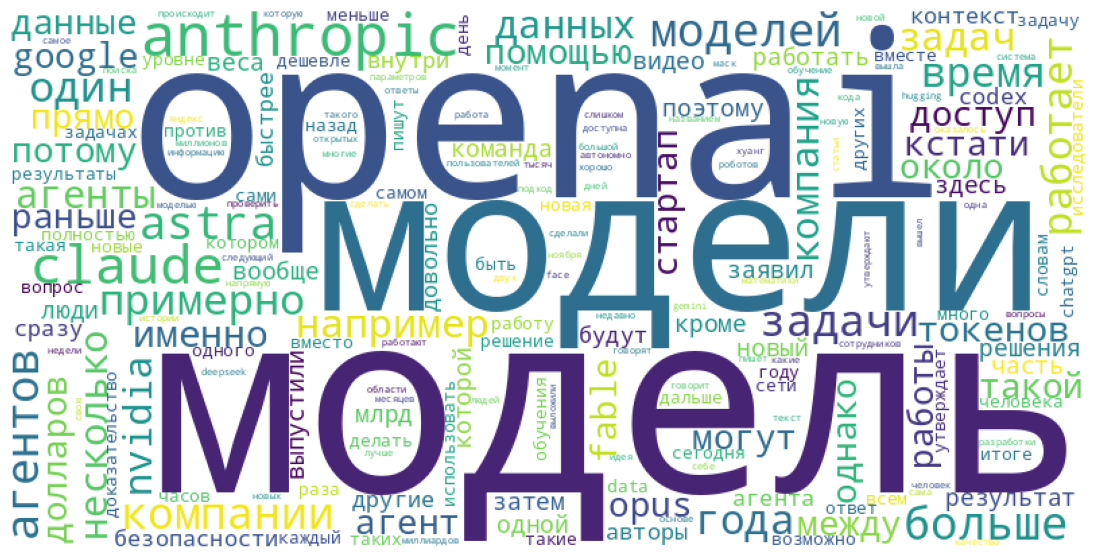

In [17]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

cloud = WordCloud(width=800, height=400, background_color="white",
                  collocations=False).generate(" ".join(words))   # collocations=False — не склеивать пары слов

plt.figure(figsize=(14, 7))
plt.imshow(cloud)
plt.axis("off")                  # убираем оси
plt.show()

💬 **Осторожно с выводами.** Это один канал за три месяца. По нему можно описать сам канал — его ритм, темы, реакции аудитории, — но не «всю отрасль» и не «весь Telegram». Для этого нужно сравнивать несколько каналов.

---
# 7. Сохраняем результат в файл

Сохраним посты в CSV — так же, как новости Lenta.ru. Этот файл можно открыть в Excel или Google Таблицах.

In [ ]:
import csv

with open("telegram_posts.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f, delimiter=";")
    writer.writerow(["date", "time", "reactions", "text"])
    for p in posts:
        writer.writerow([p["date"], p["time"], p["reactions"], p["text"]])

print("Файл сохранён, постов:", len(posts))

Файл `telegram_posts.csv` появится в панели **Файлы** слева: правая кнопка мыши → **Скачать**.

---
# Итоги

| Что | Как пишется |
|---|---|
| Прочитать HTML из файла | `open("файл.html", encoding="utf-8")` → `f.read()` |
| Все сообщения | `soup.find_all("div", class_="message")` |
| Проверить класс тега | `"service" in msg["class"]` — классы хранятся списком |
| Дата из атрибута | `post.find("div", class_="date")["title"].split()` |
| Текст без склеенных слов | `" ".join(tag.get_text(" ").split())` |
| Пропустить шаг цикла | `continue` |
| Топ по готовым числам | `Counter(словарь).most_common(5)` |
| Есть ли тег внутри тега | `if tag.find("a") is not None` |

**Главное:** выгрузка Telegram — это обычная HTML-страница. Тот же алгоритм, что и для любого сайта: посмотреть код → найти теги и классы → достать данные в цикле → сохранить.